## 1. Imports & config

In [164]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Load data

In [165]:
# Checking that the data is loaded correctly
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")

print("Train:", train.shape, "| Test:", test.shape)
print("Only in train:", set(train.columns) - set(test.columns))

# Quick look at values
display(train.head())
display(train.describe())

Train: (891, 12) | Test: (418, 11)
Only in train: {'Survived'}


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


## 3. Overview

**Shape:** 891 rows in train; test has the same columns minus `Survived`.

**Columns**

| Role | Columns |
|---|---|
| ID | PassengerId (drop as a feature) |
| Target | Survived (binary) |
| Continuous | Age, Fare |
| Count | SibSp, Parch |
| Nominal | Sex, Embarked |
| Ordinal | Pclass |
| Text / structured | Name, Ticket, Cabin |

**Missing values**
- Age: 177 (~20%) → impute, ideally by group (e.g., median per title)
- Cabin: 687 (~77%) → too sparse to use directly; extract `has_cabin` and deck letter
- Embarked: 2 → fill with the most common port
- Test: Fare has 1 missing → fill with the median Fare for that passenger's Pclass

**Takeaways**
- Fare is right-skewed with outliers → check in step 5
- Name holds titles (Mr, Mrs, Miss, Master) → extract in step 7
- SibSp + Parch → family-size feature, view as both count and category

In [166]:
# Checking null values
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

## 4. Target distribution

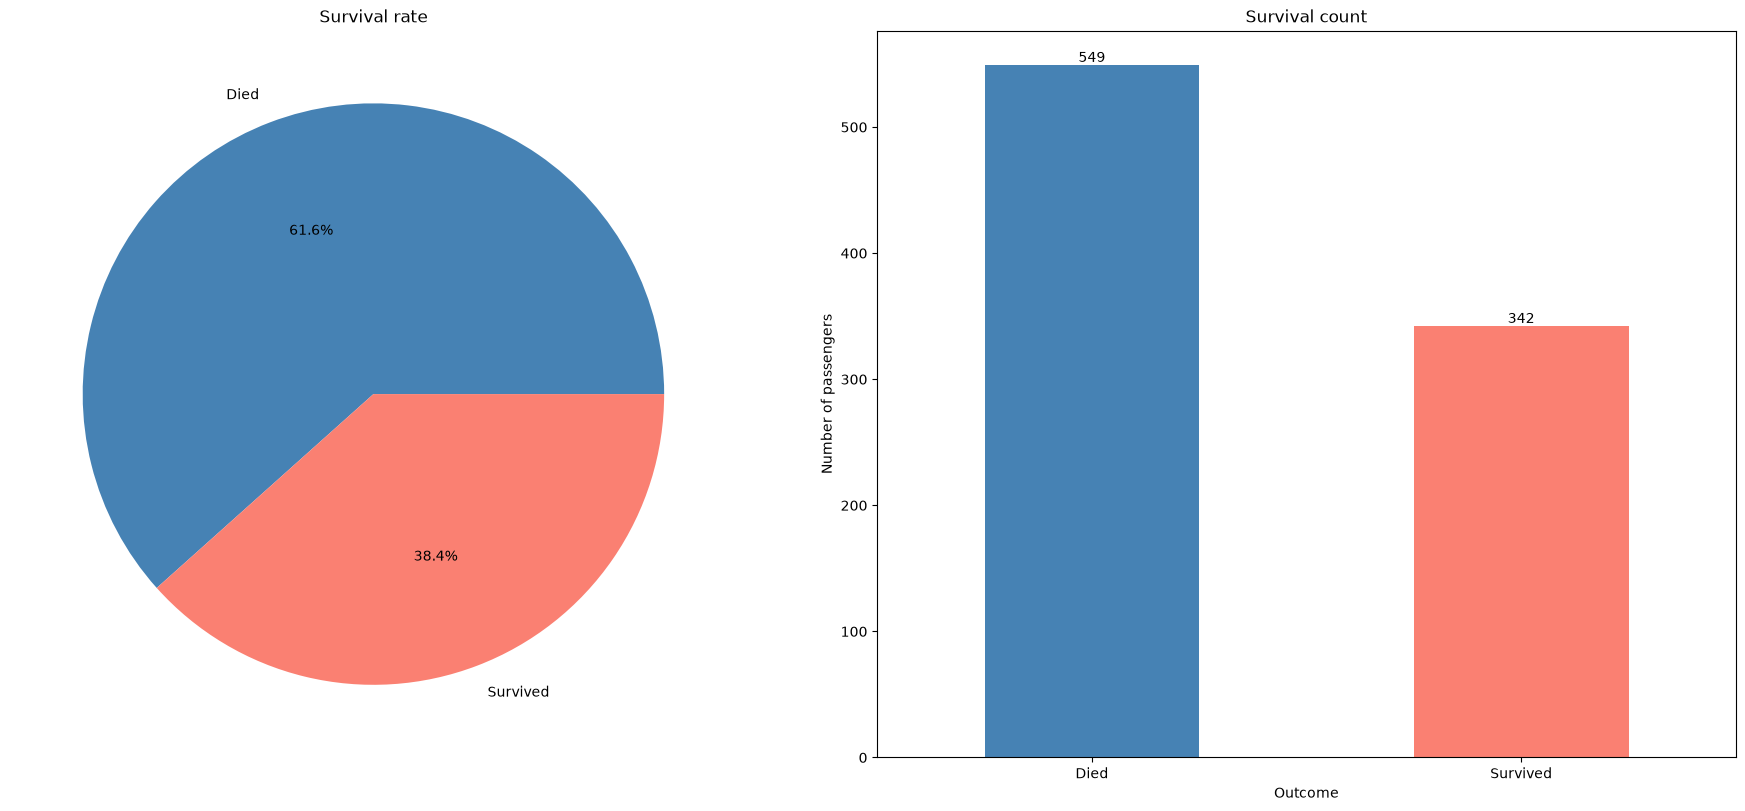

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), layout='constrained')
survived = train["Survived"].value_counts().rename({0: 'Died', 1: 'Survived'})
colors = ["salmon", "steelblue"]

survived.plot.pie(autopct='%1.1f%%', ax=ax1, colors=colors)
ax1.set_title('Survival rate')
ax1.set_ylabel('')

survived.plot.bar(ax=ax2, rot=0, color=colors)
ax2.set_title('Survival count')
ax2.set_xlabel('Outcome')
ax2.set_ylabel('Number of passengers')
ax2.bar_label(ax2.containers[0])

plt.show()

60% / 40% split is mildly imbalanced, which in practice counts as fairly balanced. We don’t need special handling, but it still tells us a few useful things:
* Our baseline is 61.6%. A model that always predicts the majority class scores 61.6% accuracy. Our model has to clearly beat that to be learning anything. So an accuracy of 65% sounds decent but is only a small gain over doing nothing.
* No resampling or class weights needed. At 60/40 tree models and logistic regression work fine

## 5. Numerical features

### Age

In [168]:
print('Oldest Passenger was of:',train["Age"].max(),'Years')
print('Youngest Passenger was of:',train["Age"].min(),'Years')
print('Average Age on the ship:',train["Age"].mean(),'Years')

Oldest Passenger was of: 80.0 Years
Youngest Passenger was of: 0.42 Years
Average Age on the ship: 29.69911764705882 Years


**Problem:** 177 missing in train (~20%), 86 in test. Missing rows are mostly
3rd class and have a lower survival rate, so missingness carries signal.

**Options considered**

| Option | Verdict |
|---|---|
| Drop rows | ✗ Loses 20% of train; test still has missing Ages |
| Global median (~28) | ✗ Blurs the child/adult signal |
| Group median by title | ✓ Chosen: cheap and accurate |
| Model-based imputation | ✗ Rarely beats group medians here |
| Leave as NaN | Only for tree models (LightGBM, XGBoost) |

**Why title:** the title in `Name` is a strong age proxy.
Master → boys, Miss → often younger women, Mrs → married women, Mr → adult men.

**Steps**
1. Add an `Age_missing` flag (0/1) before imputing, to keep the signal.
2. Extract `Title` from `Name`; map Mlle/Ms → Miss, Mme → Mrs;
   group everything else as Rare.
3. Compute median Age per Title on train + test combined
   (no target used, so no leakage).
4. Fill missing Age with the median for that passenger's Title.
5. Verify no missing values remain and re-plot Age.

In [169]:
TITLE_MAP = {
    "Mr": "Mr", "Mrs": "Mrs", "Miss": "Miss", "Master": "Master",
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Countess": "Mrs", "Lady": "Mrs", "Dona": "Mrs",
    "Capt": "Other", "Col": "Other", "Don": "Other", "Major": "Other",
    "Rev": "Other", "Sir": "Other", "Jonkheer": "Other",
}

# 1. Extract title from Name
for df in (train, test):
    df["Title"] = df["Name"].str.extract('([A-Za-z]+)\\.')

display(pd.crosstab(train["Title"], train["Sex"]).T.style.background_gradient(cmap='summer_r'))

Title,Capt,Col,Countess,Don,Dr,Jonkheer,Lady,Major,Master,Miss,Mlle,Mme,Mr,Mrs,Ms,Rev,Sir
Sex,,,,,,,,,,,,,,,,,
female,0,0,1,0,1,0,1,0,0,182,2,1,0,125,1,0,0
male,1,2,0,1,6,1,0,2,40,0,0,0,517,0,0,6,1


In [170]:
# Group rare titles per TITLE_MAP; unmapped ones (Dr — both sexes, see crosstab) go to Other
for df in (train, test):
    df["Title"] = df["Title"].map(TITLE_MAP).fillna("Other")

display(pd.crosstab(train["Title"], train["Sex"]).T.style.background_gradient(cmap='summer_r'))
train.groupby("Title")["Age"].mean()

Title,Master,Miss,Mr,Mrs,Other
Sex,,,,,
female,0,185,0,128,1
male,40,0,517,0,20


Title
Master     4.574167
Miss      21.845638
Mr        32.368090
Mrs       35.873874
Other     46.050000
Name: Age, dtype: float64

In [171]:
## Assigning the NaN Values with the Ceil values of the mean ages
train.loc[(train.Age.isnull())&(train.Title=='Mr'),'Age']=33
train.loc[(train.Age.isnull())&(train.Title=='Mrs'),'Age']=36
train.loc[(train.Age.isnull())&(train.Title=='Master'),'Age']=5
train.loc[(train.Age.isnull())&(train.Title=='Miss'),'Age']=22
train.loc[(train.Age.isnull())&(train.Title=='Other'),'Age']=46

# 5. Check
print(train["Age"].isna().sum(), test["Age"].isna().sum())  # should be 0 0

0 86


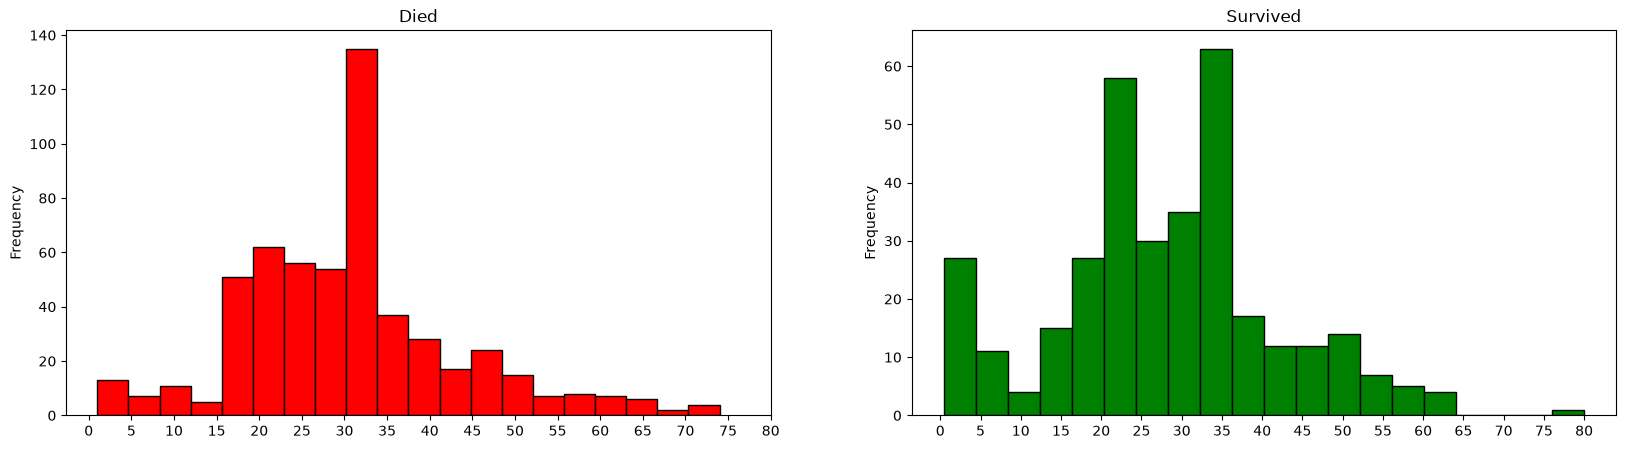

In [172]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 5))
train[train['Survived'] == 0].Age.plot.hist(ax=ax1, bins=20, edgecolor='black', color='red')
ax1.set_title('Died')
ax1.set_xticks(range(0,85,5))
train[train['Survived']==1].Age.plot.hist(ax=ax2, color='green', bins=20, edgecolor='black')
ax2.set_title('Survived')
ax2.set_xticks(range(0,85,5))
plt.show()

**Observations**:
1) Toddlers (age < 5) had high survival rate 
2) The oldes passenger survived (80 years)
3) Moste of the dead are of age 30-40

**The problem:** Age is a continuous feature: each extra year changes survival odds by the same amount in linear models. On Titanic that's wrong because children survived much more and the effect flattens for adults. We need to convert **continuous values into categorical values** using Binning. Let's divide the range from 0-80 into 5 bins of size 16 (80/5 = 16).

In [173]:
for df in (train, test):
    df["AgeBin"] = pd.cut(df["Age"], bins=[0, 16, 32, 48, 64, 80], labels=False, include_lowest=True)

display(train.head(2))
display(train["AgeBin"].value_counts().to_frame().style.background_gradient(cmap='summer'))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,AgeBin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,2


,count
AgeBin,
1,382
2,325
0,104
3,69
4,11


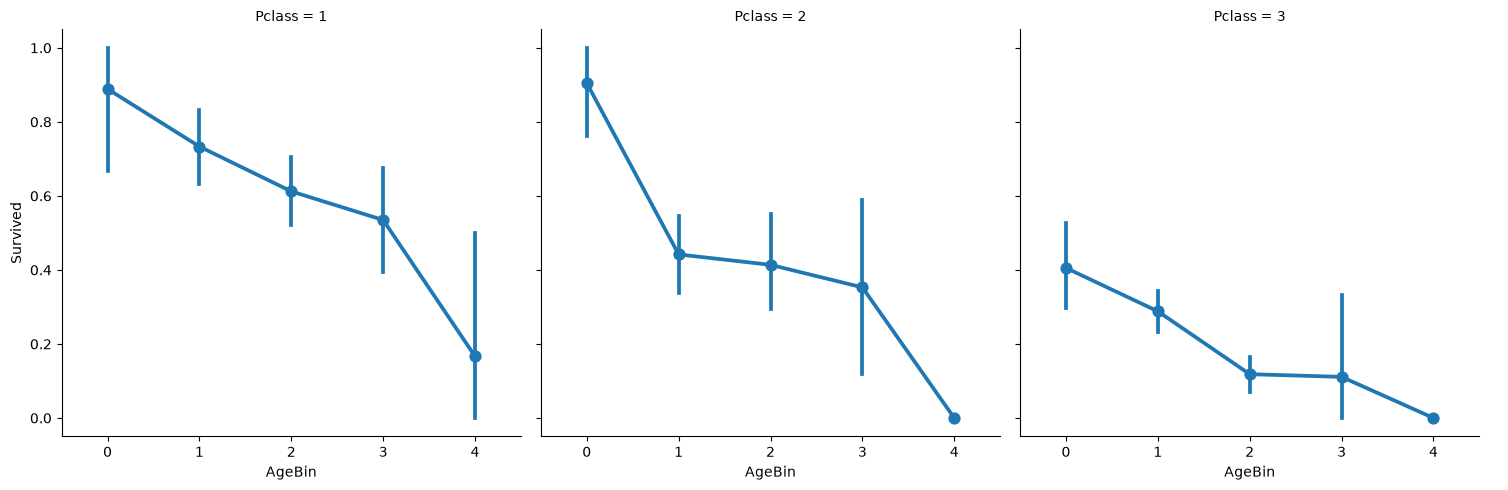

In [174]:
sns.catplot(x="AgeBin", y="Survived", data=train, col="Pclass", kind="point")
plt.show()

The survival rate decreases as the age increases irrespective of the Pclass

## 6. Categorical features

### Pclass

In [175]:
pd.crosstab(train["Pclass"], train["Survived"], margins=True).style.background_gradient(cmap='summer_r')

Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891


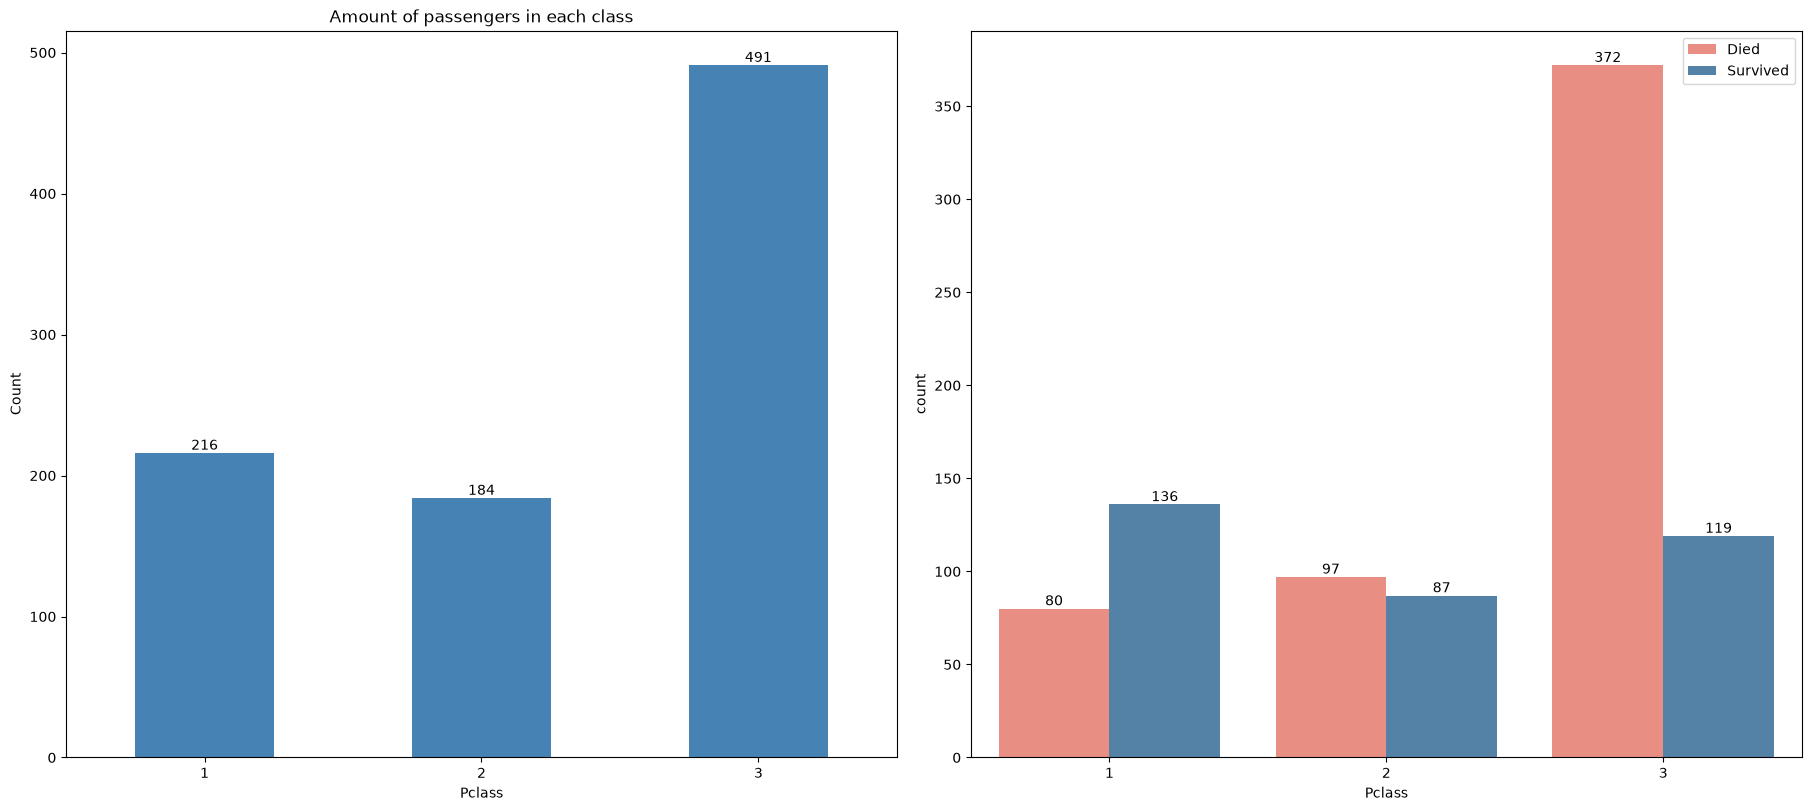

In [176]:
f, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8), layout='constrained')
train["Pclass"].value_counts().sort_index().plot.bar(ax=ax1, rot=0, color=["steelblue"])
ax1.set_title('Amount of passengers in each class')
ax1.set_ylabel('Count')
ax1.bar_label(ax1.containers[0])

sns.countplot(x="Pclass", hue="Survived", data=train, ax=ax2, palette=["salmon", "steelblue"])
ax2.legend(title=None, labels=["Died", "Survived"])
for container in ax2.containers:
    ax2.bar_label(container)
plt.show()

We can clearly see that passengers of Class 1 were given a higher priority while rescue even thoug a number of Class 3 passengers were a lot higher. For Class 1 around 63% of passengers survived while for Class 2 survival rate is around 48%.

Now let's check survival rate with Sex and Pclass together.

In [177]:
pd.crosstab([train["Sex"], train["Pclass"]], train["Survived"], margins=True).style.background_gradient(cmap='summer_r')

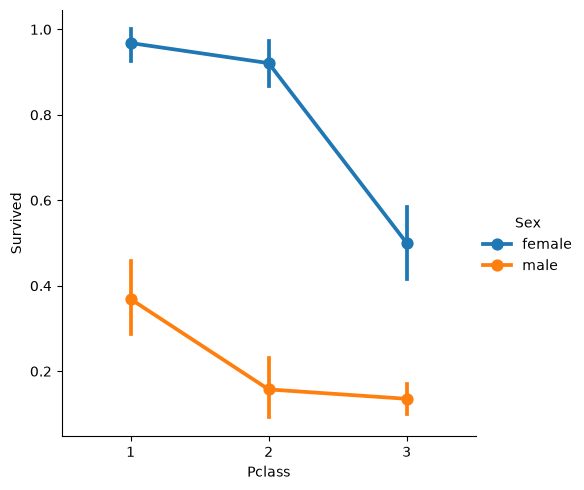

In [178]:
sns.catplot(x="Pclass", y="Survived", data=train, hue="Sex", kind="point")
plt.show()


**Observations:**
1) The gap between the lines is huge -- sex is the dominant factor. The *worst* group of women (3rd class, ~50%) still beats the *best* group of men (1st class, ~37%).
2) Both lines slope down -- class matters for both sexes.
3) The lines are not parallel -- that's an interaction. Women lose most of their advantage between 2nd and 3rd class (92% -> 50%), while men - between 1st and 2nd (37% -> 16%). "Women and children first" apparently worked almost perfectly in classes 1-2 and broke down in 3rd

This plot justifies two things:
* the sex-based baseline ("predict survived iff female" ~ 78% accuracy - the classic `gender_submission`)
* trying Sex x Pclass interaction (or Tite, which already blends sex, age, and status) as a feature

### Converting string values

Since we cannot pass strings into a ML model, we need to convert categorical features into numeric values

In [179]:
train = train.replace({
    "Sex": {"male": 0, "female": 1},
    "Embarked": {"S": 0, "C": 1, "Q": 2},
    "Title": {"Mr": 0, "Mrs": 1, "Miss": 2, "Master": 3, "Other": 4},
})

### Dropping unneeded features

1) **Name** and **PassengerId** cannot be categorized
2) **Age**: we have **AgeBin** feature so we don't need this
3) **Ticket** any random string that cannot be categorized
4) **Cabin**: a lot of NaN values and also many passengers have multiple cabins, useless

In [ ]:
train = train.drop(["Name", "PassengerId", "Age", "Ticket", "Fare", "Cabin"], axis=1)

## 8. Correlations

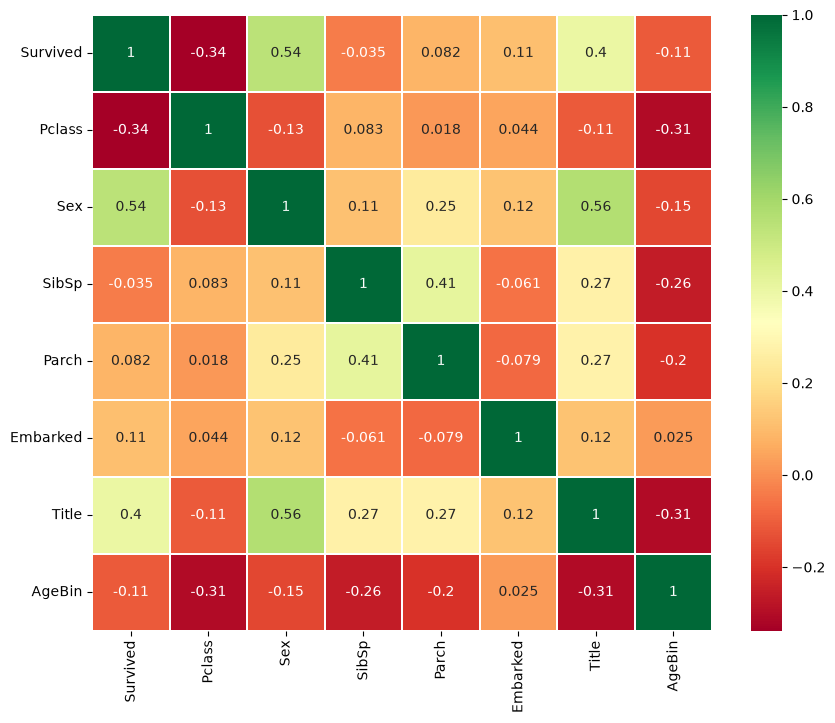

In [181]:
sns.heatmap(train.corr(),annot=True,cmap='RdYlGn',linewidths=0.2)
fig=plt.gcf()
fig.set_size_inches(10,8)
plt.show()

## 9. Train/test drift (adversarial validation)

## 10. Leakage check

## 11. Key takeaways

## 12. Baseline model